# COMP6010 Practical 01 — Probability for AI

**Work time:** 40 minutes  
**Discussion:** 20 minutes  
**Mini-project:** Build and interrogate a joint probability table for a smart commute  
**Software:** NumPy, pandas, matplotlib

## Learning objectives
- estimate joint, marginal and conditional probabilities from data
- use a joint table to answer application questions
- test whether two observed events appear independent

## Suggested timing
- **0–5 min:** answer the five review questions individually.
- **5–10 min:** run the setup and inspect the scenario/data.
- **10–35 min:** complete the implementation and experiment.
- **35–40 min:** record one result and one limitation.
- **40–60 min:** compare approaches and discuss the supplied prompts.

## Five key review questions

**Q1. What is a random variable, and what is an atomic event for three Boolean variables?**

> Your answer:  
A random variable is a function or rule that assigns a numerical or categorical value to each outcome of a random process.
An atomic event (or elementary outcome) for three Boolean variables is a complete specification of assignments for all three variables simultaneously (e.g., $\text{Rain} = \text{True}, \text{Traffic} = \text{False}, \text{OnTime} = \text{True}$). For 3 Boolean variables, there are $2^3 = 8$ possible mutually exclusive atomic events.

**Q2. What information is stored in a joint probability distribution?**

> Your answer:  
A joint probability distribution assigns a probability to every possible combination of values (every atomic event) for a set of random variables. It fully describes the statistical relationships and probabilities across all variables in the system, and the sum of all cell entries equals $1$.

**Q3. How do we obtain a marginal probability from a joint distribution?**

> Your answer: 
Through marginalization (summing out / integrating out). To get the marginal probability of a target variable $X$, you sum the joint probabilities across all possible states of all unobserved variables: $$P(X = x) = \sum_{y} P(X = x, Y = y)$$ 

**Q4. How is conditional probability related to joint probability?**

> Your answer: 
Through the product rule: $$P(A \mid B) = \frac{P(A, B)}{P(B)} \quad \text{(for } P(B) > 0\text{)}$$ Conditional probability measures the joint probability of both events $A$ and $B$ occurring, normalized by the marginal probability of the conditioning event $B$.

**Q5. What numerical equality can be used to test whether events A and B are independent?**

> Your answer:
Events $A$ and $B$ are independent if and only if: $$P(A, B) = P(A) \cdot P(B)$$ (or equivalently, $P(A \mid B) = P(A)$ when $P(B) > 0$).


## Scenario
A transport app records whether it rained, whether traffic was heavy, and whether a commuter arrived on time. The data are synthetic but generated from a plausible dependency structure:

**Rain → Heavy traffic → On-time arrival**, with an additional direct effect of rain on arrival.

Your task is to construct empirical joint tables and decide which variables are related.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 6010
rng = np.random.default_rng(RANDOM_SEED)
np.set_printoptions(precision=4, suppress=True)

In [2]:
n_days = 1000
rain = rng.random(n_days) < 0.28
p_heavy = np.where(rain, 0.70, 0.25)
heavy = rng.random(n_days) < p_heavy
p_on_time = np.where(heavy, 0.35, 0.90) - np.where(rain, 0.08, 0.0)
on_time = rng.random(n_days) < np.clip(p_on_time, 0.01, 0.99)

commute = pd.DataFrame({
    "Rain": np.where(rain, "Rain", "No rain"),
    "Traffic": np.where(heavy, "Heavy", "Light"),
    "OnTime": np.where(on_time, "On time", "Late"),
})
commute.head()

,Rain,Traffic,OnTime
0,No rain,Heavy,Late
1,No rain,Heavy,On time
2,No rain,Heavy,Late
3,No rain,Light,On time
4,No rain,Light,On time


### Task 1 — Construct a joint table
Create the normalized joint table for `Rain` and `OnTime`. Verify that all four cells sum to 1.

In [7]:
# TODO: use pd.crosstab(..., normalize="all")
joint_rain_arrival = pd.crosstab(commute["Rain"], commute["OnTime"], normalize="all")
joint_rain_arrival

OnTime,Late,On time
Rain,,
No rain,0.176,0.555
Rain,0.148,0.121


### Task 2 — Marginal and conditional probabilities
Compute:

- P(Rain)
- P(On time)
- P(On time | Rain)
- P(On time | No rain)

In [8]:
# TODO: compute the four probabilities using Boolean masks and .mean()
p_rain = (commute["Rain"] == "Rain").mean()
p_on_time = (commute["OnTime"] == "On time").mean()
p_on_time_given_rain = (commute[commute["Rain"] == "Rain"]["OnTime"] == "On time").mean()
p_on_time_given_no_rain = (commute[commute["Rain"] == "No rain"]["OnTime"] == "On time").mean()
print(f"P(Rain): {p_rain:.4f}")
print(f"P(On time): {p_on_time:.4f}")
print(f"P(On time | Rain): {p_on_time_given_rain:.4f}")
print(f"P(On time | No rain): {p_on_time_given_no_rain:.4f}")

P(Rain): 0.2690
P(On time): 0.6760
P(On time | Rain): 0.4498
P(On time | No rain): 0.7592


### Task 3 — Test empirical independence
Compare P(Rain, On time) with P(Rain)P(On time). A small difference can occur because this is a finite sample; a large difference is evidence of dependence.

In [9]:
# TODO: calculate the joint event and compare it with the product of marginals
p_rain_and_on_time = ((commute["Rain"] == "Rain") & (commute["OnTime"] == "On time")).mean()
product_of_marginals = p_rain * p_on_time
print(f"P(Rain, On time): {p_rain_and_on_time:.4f}")
print(f"P(Rain) * P(On time): {product_of_marginals:.4f}")
print(f"Difference: {abs(p_rain_and_on_time - product_of_marginals):.4f}")

P(Rain, On time): 0.1210
P(Rain) * P(On time): 0.1818
Difference: 0.0608


Conclusion: Since $P(\text{Rain}, \text{On time}) \neq P(\text{Rain}) \cdot P(\text{On time})$ ($0.1210 \neq 0.1818$), Rain and OnTime are dependent.

### Task 4 — Inspect the three-variable relation
Build the empirical joint distribution P(Rain, Traffic, OnTime), then plot the on-time rate for each weather/traffic combination.

Empirical Joint Distribution P(Rain, Traffic, OnTime):
Rain     Traffic  OnTime 
No rain  Heavy    Late       0.120
                  On time    0.062
         Light    Late       0.056
                  On time    0.493
Rain     Heavy    Late       0.130
                  On time    0.046
         Light    Late       0.018
                  On time    0.075
dtype: float64


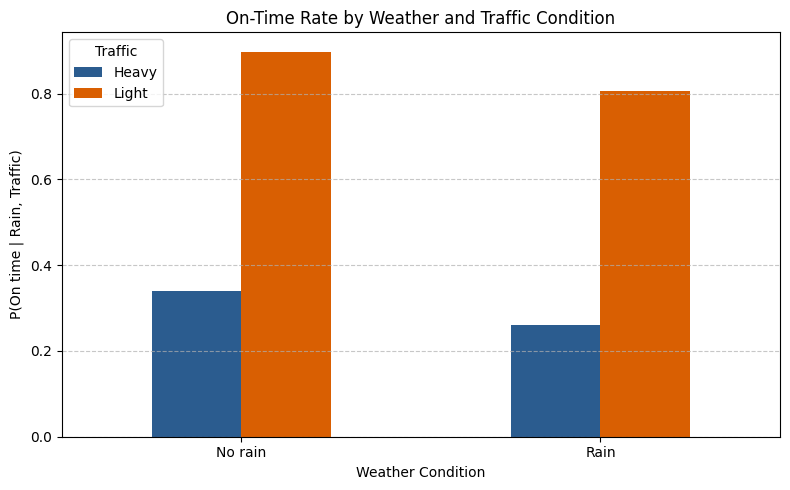

In [10]:
# TODO: use groupby(...).size()/len(commute), then calculate and plot conditional rates
# 1. Empirical joint distribution P(Rain, Traffic, OnTime)
joint_three = commute.groupby(["Rain", "Traffic", "OnTime"]).size() / len(commute)
print("Empirical Joint Distribution P(Rain, Traffic, OnTime):")
print(joint_three)
# 2. Calculate conditional on-time rate for each weather/traffic combination
conditional_rates = commute.groupby(["Rain", "Traffic"])["OnTime"].apply(lambda x: (x == "On time").mean()).unstack()
# 3. Plot conditional rates
ax = conditional_rates.plot(kind="bar", figsize=(8, 5), color=["#2b5c8f", "#d95f02"])
plt.title("On-Time Rate by Weather and Traffic Condition")
plt.xlabel("Weather Condition")
plt.ylabel("P(On time | Rain, Traffic)")
plt.xticks(rotation=0)
plt.legend(title="Traffic", labels=["Heavy", "Light"])
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

P(On time | No Rain, Heavy) = P(On time,No Rain, Heavy) / P(No Rain, Heavy regardless On Time or Not)
P(On time | No Rain, Heavy) = 0.062 / (0.062 + 0.120) = 0.3406

P(On time | No Rain, Light) = P(On time,No Rain, Heavy) / P(No Rain, Heavy regardless On Time or Not)
P(On time | No Rain, Light) = 0.493 / (0.056 + 0.493) = 0.898

### Task 5 — Interpretation
Write two sentences:

1. Which variable is most directly useful for predicting arrival?

Answer: Predictive Variable: Traffic is the most directly useful variable for predicting arrival because heavy traffic causes the largest reduction in on-time arrival rate (dropping from ~85–90% down to ~26–34%), whereas rain primarily exerts an indirect effect by increasing traffic.

2. Why does a joint table become impractical when the number of variables grows?

Answer: Impracticality of Joint Tables: A joint probability table grows exponentially as $2^n$ for $n$ binary variables, leading to the curse of dimensionality where computational storage explodes and data becomes too sparse to reliably estimate cell probabilities.


## Discussion — 20 minutes
1. Does a statistical association in the table prove that rain causes lateness?

Answer: No. Statistical dependence in an observational joint table only indicates correlation, not causation. A statistical link between rain and lateness could be confounded by other underlying variables or mediated through intermediate variables (e.g., traffic). Demonstrating causation requires causal inference methods or controlled interventions.

2. Which extra variables would improve the model, and how would the table size change?

Answer: Extra Variables: Time of day (Peak vs. Off-peak), Day of week (Weekday vs. Weekend), Road accidents, or Mode of transport.
Table Size: Adding $k$ binary variables multiplies the total number of table cells by $2^k$ (e.g., adding 2 binary variables increases the cell count from $2^3 = 8$ to $2^5 = 32$).

3. How would missing or biased observations affect these empirical probabilities?

Answer: Impact: If observations are missing non-randomly (e.g., transit logs fail to record trips during severe storms or peak congestion), selection bias will distort the relative frequencies. This results in inaccurate marginal probabilities and misleading conditional estimates of transit performance.

## Evidence to retain for a practical portfolio
- the normalized joint table
- the four probability calculations and independence comparison
- the conditional-rate plot and a two-sentence interpretation